# Single-atom Temperature (release and recapture)

Python companion to the AMO Toolkit page [Single-atom Temperature (release and recapture)](https://amotoolkit.com/pages/release-recapture.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/release-recapture.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. The trap
Polarisability from the D1 and D2 lines plus the core (atomic units), depth $U_0 = \alpha I_\mathrm{peak}/(2\epsilon_0 c)$ (Grimm et al. 2000, Eq. 2), with the peak intensity reduced by the Strehl ratio. Unlike the tweezer designer's two-level estimate, this includes both D lines, so it is the better number for alkalis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

c, eps0, kB, hbar, g, amu = 2.99792458e8, 8.8541878e-12, 1.380649e-23, 1.054572e-34, 9.80665, 1.66053906e-27
a0, Eh = 5.29177210e-11, 4.35974472e-18
alpha_au_SI = 4 * np.pi * eps0 * a0**3
SPECIES = {   # D1 (ΔE, d), D2 (ΔE, d) in atomic units, core polarisability, mass number
    "Cs": (0.050932, 4.4890, 0.053456, 6.3238, 17.35, 133), "Rb": (0.057314, 4.231, 0.058396, 5.977, 10.54, 87),
    "Na": (0.077258, 3.5246, 0.077336, 4.9838, 1.86, 23), "Li": (0.067906, 3.317, 0.067907, 4.689, 2.04, 6),
}

def polarisability_au(sp, lam):
    e1, d1, e2, d2, core, _ = SPECIES[sp]
    x = hbar * 2 * np.pi * c / lam / Eh
    return e1 * d1**2 / (3 * (e1**2 - x**2)) + e2 * d2**2 / (3 * (e2**2 - x**2)) + core

def trap(sp="Cs", lam_nm=1064, P_mW=1.5, w0_um=0.8, strehl=0.9):
    lam, w0 = lam_nm * 1e-9, w0_um * 1e-6
    a = polarisability_au(sp, lam) * alpha_au_SI
    I = strehl * 2 * P_mW * 1e-3 / (np.pi * w0**2)
    U0 = a * I / (2 * c * eps0); m = SPECIES[sp][5] * amu; zR = np.pi * w0**2 / lam
    return dict(alpha_au=a / alpha_au_SI, I_GW_m2=I / 1e9, U0_uK=U0 / kB * 1e6,
                f_r_kHz=np.sqrt(4 * U0 / (m * w0**2)) / (2 * np.pi * 1e3), f_z_kHz=np.sqrt(2 * U0 / (m * zR**2)) / (2 * np.pi * 1e3),
                zR_um=zR * 1e6, _U0=U0, _m=m, _w0=w0, _zR=zR)

tp = trap()   # page defaults: Cs, 1064 nm, 1.5 mW, w0 = 0.8 µm, Strehl 0.9
print({k: round(v, 3) for k, v in tp.items() if not k.startswith("_")})

{'alpha_au': 1163.368, 'I_GW_m2': 1.343, 'U0_uK': 351.423, 'f_r_kHz': np.float64(58.975), 'f_z_kHz': np.float64(17.654), 'zR_um': 1.89}

## 2. Monte Carlo release and recapture
Sample positions and velocities from a thermal distribution in the harmonic approximation of the trap, switch the trap off for Δt (with gravity), switch it back on, and count the atom as recaptured if its kinetic energy is below the trap depth at its new position (Tuchendler et al., PRA 78, 033425 (2008)).

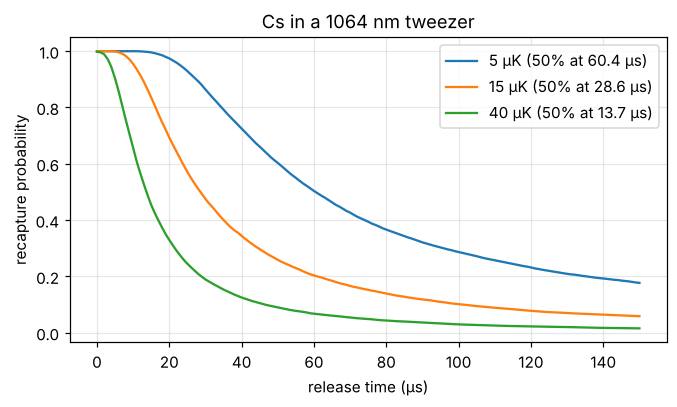

In [2]:
rng = np.random.default_rng(0)
def survival(tp, T_uK, dts_us, N=20000):
    U0, m, w0, zR = tp["_U0"], tp["_m"], tp["_w0"], tp["_zR"]
    wr, wz = 2 * np.pi * tp["f_r_kHz"] * 1e3, 2 * np.pi * tp["f_z_kHz"] * 1e3
    T = T_uK * 1e-6; sv = np.sqrt(kB * T / m)
    x, y = rng.normal(0, np.sqrt(kB * T / (m * wr**2)), (2, N)); z = rng.normal(0, np.sqrt(kB * T / (m * wz**2)), N)
    vx, vy, vz = rng.normal(0, sv, (3, N))
    out = []
    for dt in np.asarray(dts_us) * 1e-6:
        xf, yf, zf, vzf = x + vx * dt, y + vy * dt, z + vz * dt - 0.5 * g * dt**2, vz - g * dt
        KE = 0.5 * m * (vx**2 + vy**2 + vzf**2)
        wz2 = w0**2 * (1 + (zf / zR) ** 2)
        Uf = U0 * w0**2 / wz2 * np.exp(-2 * (xf**2 + yf**2) / wz2)
        out.append(np.mean(KE < Uf))
    return np.array(out)

dts = np.linspace(0, 150, 151)
half = {}
for T in (5, 15, 40):
    S = survival(tp, T, dts)
    i = np.argmax(S <= 0.5); half[T] = np.interp(0.5, [S[i], S[i - 1]], [dts[i], dts[i - 1]])
    plt.plot(dts, S, label=f"{T} µK (50% at {half[T]:.1f} µs)")
plt.xlabel("release time (µs)"); plt.ylabel("recapture probability"); plt.legend(); plt.title("Cs in a 1064 nm tweezer")

## 3. Fitting a measured curve
To extract T from data, run the simulation on a grid of temperatures and minimise χ² against your measured survival (with binomial error bars). The 50% time falls with temperature, but more slowly than the naive ballistic 1/√T: the depth also sets an energy cut-off, so t₅₀·√T is not constant (course problem, week 9):

In [3]:
for T in half: print(f"T = {T:>2} µK: t50 = {half[T]:.1f} µs,  t50·√T = {half[T]*np.sqrt(T):.0f}")

T =  5 µK: t50 = 60.4 µs,  t50·√T = 135
T = 15 µK: t50 = 28.6 µs,  t50·√T = 111
T = 40 µK: t50 = 13.7 µs,  t50·√T = 87

**Read with care:** a classical model. It assumes a harmonic thermal start and an ideal Gaussian focus; the Strehl ratio rescales the depth only. Real aberrations change the trap shape, and a mis-set depth biases the inferred temperature (course problem, week 9).

## 4. Check against the page
Trap parameters must agree exactly; the Monte Carlo half-lives agree within the page's statistical noise (600 samples there).

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(alpha_au=tp["alpha_au"], I_GW_m2=tp["I_GW_m2"], U0_uK=tp["U0_uK"], f_r_kHz=tp["f_r_kHz"], f_z_kHz=tp["f_z_kHz"], zR_um=tp["zR_um"])
DECIMALS = dict(alpha_au=1, I_GW_m2=2, U0_uK=0, f_r_kHz=1, f_z_kHz=2, zR_um=2)
page = dict(alpha_au=1163.4, I_GW_m2=1.34, U0_uK=351, f_r_kHz=59.0, f_z_kHz=17.65, zR_um=1.89)
check(ours, page)
page_half = {5: 59.9, 15: 28.3, 40: 13.7}
for T, h in page_half.items():
    assert abs(half[T] - h) / h < 0.12, (T, half[T], h)
    print(f"t50 at {T} µK: notebook {half[T]:.1f} µs, page {h} µs (Monte Carlo, within 12%)")

    alpha_au: notebook 1163         page 1163.4     OK
     I_GW_m2: notebook 1.343        page 1.34       OK
       U0_uK: notebook 351.4        page 351        OK
     f_r_kHz: notebook 58.97        page 59         OK
     f_z_kHz: notebook 17.65        page 17.65      OK
       zR_um: notebook 1.89         page 1.89       OK
All values match the page.
t50 at 5 µK: notebook 60.4 µs, page 59.9 µs (Monte Carlo, within 12%)
t50 at 15 µK: notebook 28.6 µs, page 28.3 µs (Monte Carlo, within 12%)
t50 at 40 µK: notebook 13.7 µs, page 13.7 µs (Monte Carlo, within 12%)